# Experiment 2: Comprehensive Text Preprocessing Pipeline for NLP

### Problem Statement:
Given a collection of raw text documents, develop a preprocessing pipeline that performs tokenization, stop-word removal, normalization, stemming, and lemmatization to prepare the data for NLP applications.


In [1]:
import re
import string
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize, WordPunctTokenizer, WhitespaceTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk import pos_tag

# Download necessary NLTK corpora
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

nlp = spacy.load("en_core_web_sm")
print("Libraries and linguistic corpora loaded successfully.")


Libraries and linguistic corpora loaded successfully.


In [2]:
raw_documents = [
    "<p>Natural Language Processing (NLP) isn't just about parsing text! It's revolutionizing healthcare & finance.</p>",
    "<div>The researchers were analyzing, optimizing, and organizing multi-modal datasets at https://ai-lab.org.</div>",
    "Patients' symptoms were thoroughly studied; studies demonstrated that early detection saves lives!",
    "He won't believe that better algorithms yielded 99.8% accuracy on unseen experimental evaluations.",
    "<span>Deep neural networks are learning, have learned, and will learn complex syntactic structures.</span>"
]

print("--- Sample Raw Documents ---")
for i, doc in enumerate(raw_documents, 1):
    print(f"Doc {i}: {doc}")


--- Sample Raw Documents ---
Doc 1: <p>Natural Language Processing (NLP) isn't just about parsing text! It's revolutionizing healthcare & finance.</p>
Doc 2: <div>The researchers were analyzing, optimizing, and organizing multi-modal datasets at https://ai-lab.org.</div>
Doc 3: Patients' symptoms were thoroughly studied; studies demonstrated that early detection saves lives!
Doc 4: He won't believe that better algorithms yielded 99.8% accuracy on unseen experimental evaluations.
Doc 5: <span>Deep neural networks are learning, have learned, and will learn complex syntactic structures.</span>


In [3]:
CONTRACTION_MAP = {
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "won't": "will not",
    "wouldn't": "would not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "can't": "cannot",
    "couldn't": "could not",
    "shouldn't": "should not",
    "it's": "it is",
    "that's": "that is",
    "what's": "what is",
    "he's": "he is",
    "she's": "she is",
    "they're": "they are",
    "we're": "we are",
    "you're": "you are"
}

def clean_and_normalize(text):
    # 1. Strip HTML tags
    clean = re.sub(r'<[^>]+>', ' ', text)
    # 2. Lowercase
    clean = clean.lower()
    # 3. Expand contractions
    for contraction, expansion in CONTRACTION_MAP.items():
        clean = re.sub(r'\b' + re.escape(contraction) + r'\b', expansion, clean)
    # 4. Remove URLs
    clean = re.sub(r'http[s]?://\S+', ' ', clean)
    # 5. Remove punctuation and digits (preserving standard alphabetic tokens)
    clean = re.sub(r'[^a-z\s]', ' ', clean)
    # 6. Normalize whitespace
    clean = re.sub(r'\s+', ' ', clean).strip()
    return clean

cleaned_docs = [clean_and_normalize(doc) for doc in raw_documents]

df_clean_compare = pd.DataFrame({
    "Original Text": [d[:60] + "..." for d in raw_documents],
    "Normalized Text": cleaned_docs
})
print("--- Text Normalization Comparison ---")
print(df_clean_compare.to_string(index=False))


--- Text Normalization Comparison ---
                                                  Original Text                                                                                         Normalized Text
<p>Natural Language Processing (NLP) isn't just about parsin... natural language processing nlp is not just about parsing text it is revolutionizing healthcare finance
<div>The researchers were analyzing, optimizing, and organiz...                        the researchers were analyzing optimizing and organizing multi modal datasets at
Patients' symptoms were thoroughly studied; studies demonstr...         patients symptoms were thoroughly studied studies demonstrated that early detection saves lives
He won't believe that better algorithms yielded 99.8% accura...          he will not believe that better algorithms yielded accuracy on unseen experimental evaluations
<span>Deep neural networks are learning, have learned, and w...              deep neural networks are learning have learne

In [4]:
sample_sentence = "Dr. Smith's algorithm isn't slow; it achieved 98.5% efficiency on Jan 20th!"

tok_whitespace = sample_sentence.split()
tok_wordpunct = WordPunctTokenizer().tokenize(sample_sentence)
tok_nltk_treebank = word_tokenize(sample_sentence)
tok_spacy = [t.text for t in nlp(sample_sentence)]

print(f"Sample Input: {sample_sentence}\n")
print(f"1. Whitespace Split ({len(tok_whitespace)} tokens) :\n   {tok_whitespace}\n")
print(f"2. WordPunctTokenizer ({len(tok_wordpunct)} tokens):\n   {tok_wordpunct}\n")
print(f"3. NLTK Treebank ({len(tok_nltk_treebank)} tokens)     :\n   {tok_nltk_treebank}\n")
print(f"4. SpaCy Tokenizer ({len(tok_spacy)} tokens)        :\n   {tok_spacy}")


Sample Input: Dr. Smith's algorithm isn't slow; it achieved 98.5% efficiency on Jan 20th!

1. Whitespace Split (12 tokens) :
   ['Dr.', "Smith's", 'algorithm', "isn't", 'slow;', 'it', 'achieved', '98.5%', 'efficiency', 'on', 'Jan', '20th!']

2. WordPunctTokenizer (22 tokens):
   ['Dr', '.', 'Smith', "'", 's', 'algorithm', 'isn', "'", 't', 'slow', ';', 'it', 'achieved', '98', '.', '5', '%', 'efficiency', 'on', 'Jan', '20th', '!']

3. NLTK Treebank (17 tokens)     :
   ['Dr.', 'Smith', "'s", 'algorithm', 'is', "n't", 'slow', ';', 'it', 'achieved', '98.5', '%', 'efficiency', 'on', 'Jan', '20th', '!']

4. SpaCy Tokenizer (17 tokens)        :
   ['Dr.', 'Smith', "'s", 'algorithm', 'is', "n't", 'slow', ';', 'it', 'achieved', '98.5', '%', 'efficiency', 'on', 'Jan', '20th', '!']


In [5]:
default_stopwords = set(stopwords.words('english'))
custom_stopwords = default_stopwords.union({"etc", "also", "using", "p", "div", "span"})

tokenized_docs = [word_tokenize(doc) for doc in cleaned_docs]
filtered_docs = [[w for w in doc if w not in custom_stopwords and len(w) > 2] for doc in tokenized_docs]

total_raw_tokens = sum(len(d) for d in tokenized_docs)
total_filtered_tokens = sum(len(d) for d in filtered_docs)
reduction_pct = ((total_raw_tokens - total_filtered_tokens) / total_raw_tokens) * 100

print(f"Total tokens before stopword removal: {total_raw_tokens}")
print(f"Total tokens after stopword removal : {total_filtered_tokens}")
print(f"Token reduction percentage           : {reduction_pct:.2f}%")
print(f"Sample filtered document 1: {filtered_docs[0]}")


Total tokens before stopword removal: 64
Total tokens after stopword removal : 43
Token reduction percentage           : 32.81%
Sample filtered document 1: ['natural', 'language', 'processing', 'nlp', 'parsing', 'text', 'revolutionizing', 'healthcare', 'finance']


In [6]:
porter = PorterStemmer()
snowball = SnowballStemmer("english")
lancaster = LancasterStemmer()

sample_words = [
    "studies", "studying", "studied",
    "organization", "organizing", "organizes",
    "optimization", "optimizing", "optimizer",
    "generously", "generation", "generic",
    "universe", "university", "universal"
]

stem_comparison = []
for word in sample_words:
    stem_comparison.append({
        "Original Word": word,
        "Porter Stem": porter.stem(word),
        "Snowball Stem": snowball.stem(word),
        "Lancaster Stem": lancaster.stem(word)
    })

df_stems = pd.DataFrame(stem_comparison)
print("--- Comparison of Stemming Algorithms ---")
print(df_stems.to_string(index=False))


--- Comparison of Stemming Algorithms ---
Original Word Porter Stem Snowball Stem Lancaster Stem
      studies       studi         studi          study
     studying       studi         studi          study
      studied       studi         studi          study
 organization       organ         organ            org
   organizing       organ         organ            org
    organizes       organ         organ            org
 optimization       optim         optim          optim
   optimizing       optim         optim          optim
    optimizer       optim         optim          optim
   generously       gener      generous            gen
   generation       gener       generat            gen
      generic       gener       generic            gen
     universe     univers       univers        univers
   university     univers       univers        univers
    universal     univers       univers        univers


In [7]:
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(nltk_tag):
    if nltk_tag.startswith('J'):
        return wordnet.ADJ
    elif nltk_tag.startswith('V'):
        return wordnet.VERB
    elif nltk_tag.startswith('N'):
        return wordnet.NOUN
    elif nltk_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

test_tokens = ["better", "studies", "running", "optimization", "feet", "wolves", "was"]
pos_tagged = pos_tag(test_tokens)

lemma_results = []
for word, tag in pos_tagged:
    wn_pos = get_wordnet_pos(tag)
    naive_lemma = lemmatizer.lemmatize(word) # Default is NOUN
    pos_aware_lemma = lemmatizer.lemmatize(word, pos=wn_pos)
    spacy_lemma = [t.lemma_ for t in nlp(word)][0]
    
    lemma_results.append({
        "Token": word,
        "POS Tag": tag,
        "WordNet POS": wn_pos,
        "Naive Lemma (Noun)": naive_lemma,
        "POS-Aware WordNet Lemma": pos_aware_lemma,
        "SpaCy Lemma": spacy_lemma
    })

df_lemmas = pd.DataFrame(lemma_results)
print("--- Lemmatization Comparison: Naive vs POS-Aware vs SpaCy ---")
print(df_lemmas.to_string(index=False))


--- Lemmatization Comparison: Naive vs POS-Aware vs SpaCy ---
       Token POS Tag WordNet POS Naive Lemma (Noun) POS-Aware WordNet Lemma  SpaCy Lemma
      better     JJR           a             better                    good         well
     studies     NNS           n              study                   study        study
     running     VBG           v            running                     run          run
optimization      NN           n       optimization            optimization optimization
        feet     NNS           n               foot                    foot         foot
      wolves     NNS           n               wolf                    wolf         wolf
         was     VBD           v                 wa                      be           be


In [8]:
class NLPPreprocessingPipeline:
    def __init__(self, mode='lemmatize', use_spacy=False, remove_stopwords=True):
        self.mode = mode # 'stem' or 'lemmatize'
        self.use_spacy = use_spacy
        self.remove_stopwords = remove_stopwords
        self.stopwords = set(stopwords.words('english'))
        self.stemmer = SnowballStemmer('english')
        self.lemmatizer = WordNetLemmatizer()
        self.spacy_nlp = nlp

    def preprocess_text(self, text):
        # 1. Clean and normalize
        cleaned = clean_and_normalize(text)
        
        # 2. SpaCy Branch
        if self.use_spacy:
            doc = self.spacy_nlp(cleaned)
            tokens = []
            for token in doc:
                if self.remove_stopwords and (token.is_stop or token.text in self.stopwords):
                    continue
                if len(token.text) <= 2:
                    continue
                if self.mode == 'lemmatize':
                    tokens.append(token.lemma_)
                elif self.mode == 'stem':
                    tokens.append(self.stemmer.stem(token.text))
                else:
                    tokens.append(token.text)
            return tokens
        
        # 3. NLTK Branch
        raw_tokens = word_tokenize(cleaned)
        if self.remove_stopwords:
            raw_tokens = [w for w in raw_tokens if w not in self.stopwords and len(w) > 2]
        
        if self.mode == 'stem':
            return [self.stemmer.stem(w) for w in raw_tokens]
        elif self.mode == 'lemmatize':
            tagged = pos_tag(raw_tokens)
            return [self.lemmatizer.lemmatize(w, pos=get_wordnet_pos(tag)) for w, tag in tagged]
        else:
            return raw_tokens

    def process_corpus(self, corpus):
        return [self.preprocess_text(doc) for doc in corpus]

# Execute complete pipeline on our raw documents
pipeline_lemmatizer = NLPPreprocessingPipeline(mode='lemmatize')
processed_corpus = pipeline_lemmatizer.process_corpus(raw_documents)

print("--- End-to-End Preprocessing Pipeline Output ---")
for i, (orig, processed) in enumerate(zip(raw_documents, processed_corpus), 1):
    print(f"Doc {i} RAW      : {orig}")
    print(f"Doc {i} PROCESSED: {processed}\n")


--- End-to-End Preprocessing Pipeline Output ---
Doc 1 RAW      : <p>Natural Language Processing (NLP) isn't just about parsing text! It's revolutionizing healthcare & finance.</p>
Doc 1 PROCESSED: ['natural', 'language', 'processing', 'nlp', 'parse', 'text', 'revolutionize', 'healthcare', 'finance']

Doc 2 RAW      : <div>The researchers were analyzing, optimizing, and organizing multi-modal datasets at https://ai-lab.org.</div>
Doc 2 PROCESSED: ['researcher', 'analyze', 'optimize', 'organize', 'multi', 'modal', 'datasets']

Doc 3 RAW      : Patients' symptoms were thoroughly studied; studies demonstrated that early detection saves lives!
Doc 3 PROCESSED: ['patient', 'symptom', 'thoroughly', 'studied', 'study', 'demonstrate', 'early', 'detection', 'save', 'life']

Doc 4 RAW      : He won't believe that better algorithms yielded 99.8% accuracy on unseen experimental evaluations.
Doc 4 PROCESSED: ['believe', 'good', 'algorithm', 'yield', 'accuracy', 'unseen', 'experimental', 'evaluation

Raw Corpus Total Tokens        : 60
Raw Corpus Unique Vocabulary   : 57
Processed Corpus Total Tokens  : 43
Processed Unique Vocabulary    : 41
Dimensionality Reduction Ratio : 28.07%


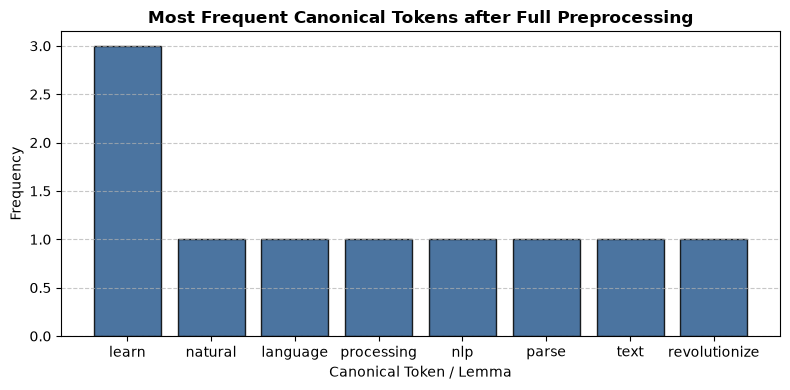

In [9]:
# Compute vocabularies
all_raw_tokens = [w.lower() for doc in raw_documents for w in word_tokenize(re.sub(r'<[^>]+>', ' ', doc)) if w.isalnum()]
all_processed_tokens = [w for doc in processed_corpus for w in doc]

raw_vocab = set(all_raw_tokens)
processed_vocab = set(all_processed_tokens)

print(f"Raw Corpus Total Tokens        : {len(all_raw_tokens)}")
print(f"Raw Corpus Unique Vocabulary   : {len(raw_vocab)}")
print(f"Processed Corpus Total Tokens  : {len(all_processed_tokens)}")
print(f"Processed Unique Vocabulary    : {len(processed_vocab)}")
print(f"Dimensionality Reduction Ratio : {(1 - len(processed_vocab)/len(raw_vocab))*100:.2f}%")

# Plot Top Most Frequent Tokens in Processed Corpus
counts = Counter(all_processed_tokens).most_common(8)
tokens, freqs = zip(*counts)

plt.figure(figsize=(8, 4))
plt.bar(tokens, freqs, color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.title("Most Frequent Canonical Tokens after Full Preprocessing", fontsize=12, fontweight='bold')
plt.xlabel("Canonical Token / Lemma", fontsize=10)
plt.ylabel("Frequency", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
